# Assignment 2 — Kaggle Digit Recognizer

**Objective:** predict the digit (0–9) of 28,000 handwritten 28×28 grayscale images, measured by accuracy.

1. Data pipeline: CSV → `Dataset`/`DataLoader`, pixels normalised, tensors of shape `[B, 1, 28, 28]`, stratified hold-out validation split.
2. **MLP baseline** (fully connected, like Session 9).
3. **CNN** with 2 convolutional blocks.
4. **Improvement**: BatchNorm + Dropout + data augmentation + learning-rate scheduler.
5. Analysis: learning curves, confusion matrix, misclassified digits.
6. Kaggle submission file.


## 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import digit_recognizer as dr
from digit_recognizer import (
    load_train_csv, load_test_csv, split_train_val, compute_mean_std,
    make_loaders, make_test_loader, build_model, count_parameters,
    fit, predict_labels, make_submission, check_submission,
    plot_samples, plot_history, plot_confusion_matrix, plot_misclassified,
    set_seed, get_device,
)

SEED = 42
set_seed(SEED)
device = get_device()

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

print("Package version:", dr.__version__)
print("PyTorch:", torch.__version__, "| device:", device)

Package version: 0.1.0
PyTorch: 2.14.1 | device: mps


## 2. Load and inspect the data

Data: `train.csv` has 42,000 labelled grayscale images of 28x28 pixels (784 pixel columns + `label`). test.csv has 28,000 unlabelled images for test.



In [2]:
X_all, y_all = load_train_csv(DATA_DIR / "train.csv")
X_test = load_test_csv(DATA_DIR / "test.csv")

print("Train images:", X_all.shape, X_all.dtype, "| labels:", y_all.shape)
print("Test images: ", X_test.shape)
print("Pixel range:", X_all.min(), "to", X_all.max())

Train images: (42000, 28, 28) uint8 | labels: (42000,)
Test images:  (28000, 28, 28)
Pixel range: 0 to 255


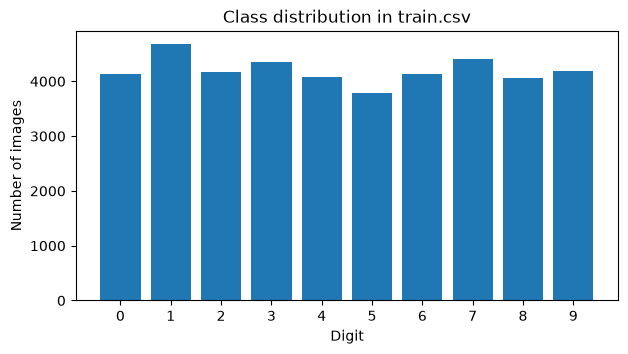

{0: np.int64(4132), 1: np.int64(4684), 2: np.int64(4177), 3: np.int64(4351), 4: np.int64(4072), 5: np.int64(3795), 6: np.int64(4137), 7: np.int64(4401), 8: np.int64(4063), 9: np.int64(4188)}


In [3]:
counts = np.bincount(y_all, minlength=10)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(10), counts, color="C0")
ax.set_xticks(range(10))
ax.set_xlabel("Digit")
ax.set_ylabel("Number of images")
ax.set_title("Class distribution in train.csv")
fig.savefig(RESULTS_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(dict(enumerate(counts)))

The classes are roughly balanced - accuracy is a sensible metric.

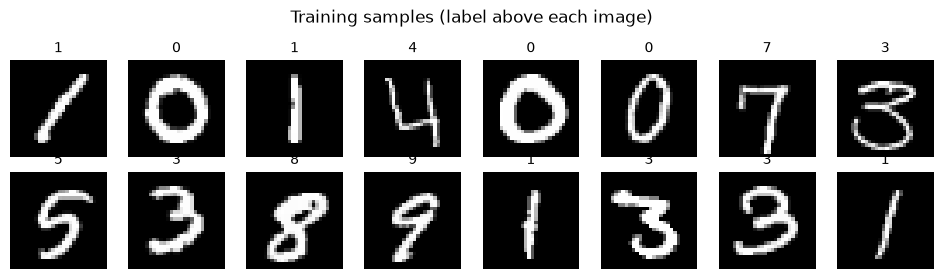

In [4]:
plot_samples(X_all, y_all, n=16, path=RESULTS_DIR / "sample_digits.png")
plt.show()

## 3. Validation split and normalisation

- **Hold-out validation**: 10% of the labelled data, **stratified** the proportion of the numbers. 
    - kaggle test set is  used once in the final predictions.
- **Normalisation**:[0, 1] scaling of pixel and then standardised with  mean and std. of the training split only . Then the same numbers are use in test and validate 
- Images are reshaped to `[B, 1, 28, 28]` 

In [5]:
X_train, X_val, y_train, y_val = split_train_val(X_all, y_all, val_size=0.1, seed=SEED)
MEAN, STD = compute_mean_std(X_train)
print(f"train: {X_train.shape[0]} images | validation: {X_val.shape[0]} images")
print(f"mean = {MEAN:.4f}, std = {STD:.4f}")

BATCH_SIZE = 128
train_loader, val_loader = make_loaders(X_train, y_train, X_val, y_val, MEAN, STD,
                                        batch_size=BATCH_SIZE, augment=False, seed=SEED)
xb, yb = next(iter(train_loader))
print("Batch of images:", tuple(xb.shape), "| batch of labels:", tuple(yb.shape))

train: 37800 images | validation: 4200 images
mean = 0.1310, std = 0.3085
Batch of images: (128, 1, 28, 28) | batch of labels: (128,)


## 4. MLP baseline

In [6]:
set_seed(SEED)
mlp = build_model("mlp")
print(mlp)
print("Trainable parameters:", count_parameters(mlp))
hist_mlp = fit(mlp, train_loader, val_loader, device, epochs=10, lr=1e-3)

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 235146
Epoch  1/10: train_loss=0.3309 train_acc=0.9033 val_loss=0.1676 val_acc=0.9493 (1s)
Epoch  2/10: train_loss=0.1291 train_acc=0.9611 val_loss=0.1212 val_acc=0.9655 (1s)
Epoch  3/10: train_loss=0.0852 train_acc=0.9739 val_loss=0.1002 val_acc=0.9707 (1s)
Epoch  4/10: train_loss=0.0590 train_acc=0.9812 val_loss=0.0928 val_acc=0.9726 (1s)
Epoch  5/10: train_loss=0.0456 train_acc=0.9852 val_loss=0.0926 val_acc=0.9724 (1s)
Epoch  6/10: train_loss=0.0366 train_acc=0.9881 val_loss=0.0911 val_acc=0.9760 (1s)
Epoch  7/10: train_loss=0.0296 train_acc=0.9903 val_loss=0.0951 val_acc=0.9764 (1s)
Epoch  8/10: train_loss=0.0251 train_acc=0.9919 val_loss=0.0914 val_acc=0.9767 (1s)
Epoch  9

## 5. CNN with 2 convolutional blocks

In [7]:
set_seed(SEED)
cnn = build_model("cnn")
print(cnn)
print("Trainable parameters:", count_parameters(cnn))
print("Output shape:", tuple(cnn(xb[:4]).shape))
hist_cnn = fit(cnn, train_loader, val_loader, device, epochs=10, lr=1e-3)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 421642
Output shape: (4, 10)
Epoch  1/10: train_loss=0.2341 train_acc=0.9294 val_loss=0.0780 val_acc=0.9764 (5s)
Epoch  2/10: train_loss=0.0558 train_acc=0.9822 val_loss=0.0551 val_acc=0.9824 (5s)
Epoch  3/10: train_loss=0.0388 train_acc=0.9878 val_loss=0.0398 val_acc=0.9881 (6s)
Epoch  4/10: train_loss=0.0271 train_acc=0.9912 val_loss=0.0492 val_acc=0.9864 (6s)
Epoch  

## 6. Improvement: BatchNorm + Dropout + data augmentation + LR scheduler

CHANGE: 
- `Two Conv → BatchNorm2d → ReLU` per block; - `BatchNorm2d` gives us faster and stable training, stabilizes the feature maps.
- `Dropout2d(0.1)` end of block, `Dropout(0.4)` in the classifier; - regularization
- Data augmentation on the training set; - its gets the difference in the human writing 
- `CosineAnnealingLR` scheduler; - starts with big learning rate steps and tru the time it goes smaller 
- Label smoothing 0.1; - over-confident logic are prevented

The architecture still has **2 convolutional blocks**, so the comparison with the CNN above is fair.

In [8]:
train_loader_aug, _ = make_loaders(X_train, y_train, X_val, y_val, MEAN, STD,
                                   batch_size=BATCH_SIZE, augment=True, seed=SEED)

set_seed(SEED)
improved = build_model("improved_cnn")
print(improved)
print("Trainable parameters:", count_parameters(improved))
hist_improved = fit(improved, train_loader_aug, val_loader, device, epochs=15, lr=1e-3,
                    scheduler="cosine", label_smoothing=0.1)

ImprovedCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): Sequential(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout2d(p=0.1, inplace=False)
    (4): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (5): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNor

## 7. Comparison and learning curves

In [9]:
histories = {"MLP": hist_mlp, "CNN": hist_cnn, "Improved CNN": hist_improved}
summary = pd.DataFrame([
    {
        "model": name,
        "parameters": count_parameters(m),
        "epochs": len(h["val_acc"]),
        "best epoch": h["best_epoch"],
        "final train acc": round(h["train_acc"][-1], 4),
        "best val acc": round(h["best_val_acc"], 4),
        f"val errors (of {len(y_val)})": int(round((1 - h["best_val_acc"]) * len(y_val))),
    }
    for (name, h), m in zip(histories.items(), [mlp, cnn, improved])
]).set_index("model")
summary.to_csv(RESULTS_DIR / "model_comparison.csv")
summary

,parameters,epochs,best epoch,final train acc,best val acc,val errors (of 4200)
model,,,,,,
MLP,235146,10,9,0.9946,0.9786,90
CNN,421642,10,7,0.9972,0.9898,43
Improved CNN,871082,15,15,0.9928,0.9962,16


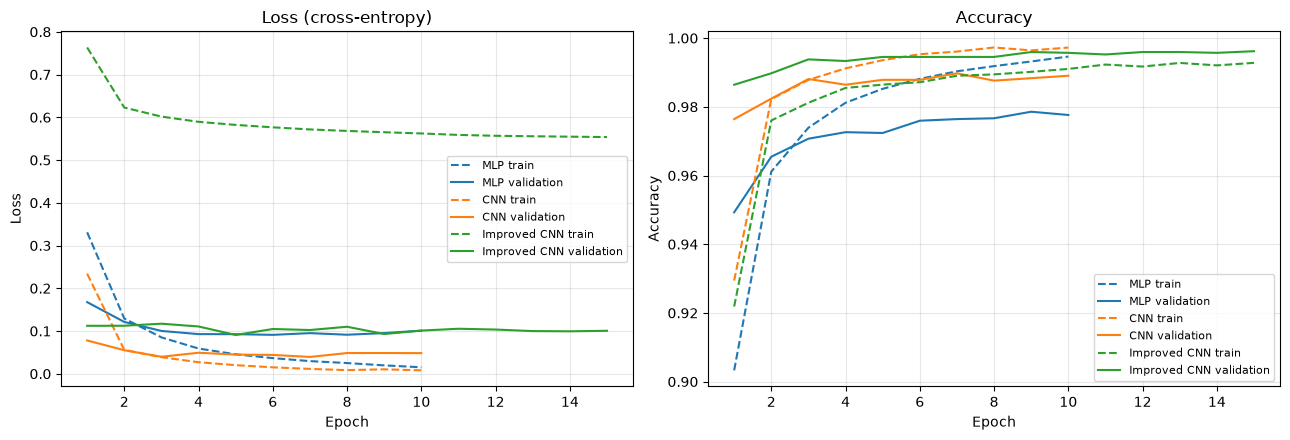

In [10]:
plot_history(histories, path=RESULTS_DIR / "learning_curves.png")
plt.show()

**How to read the curves.** Dashed lines are training, solid lines are validation.

- **MLP**: training accuracy - 0.995 while validation was around 0.975–0.979,means thatit overfits and stops improving.
- **CNN**: validation accuracy - 0.99 while training accuracy 0.998 keeps going up but validation loss starts to go up after epoch 7, means that there is signs of overfitting.
- **Improved CNN**: validation accuracy is above training accuracy for the whole run. 
    - Augmentation and dropout - training harder on purpose and stops at validation time. 
    - Its training loss stays close 0.55 - label smoothing never lets the loss reach 0
        - validation loss - cross-entropy. Validation accuracy goes up to 0.9964 as the cosine schedule lowers  learning rate.

## 8. Error analysis on the validation set (improved CNN)

Validation accuracy: 0.9962


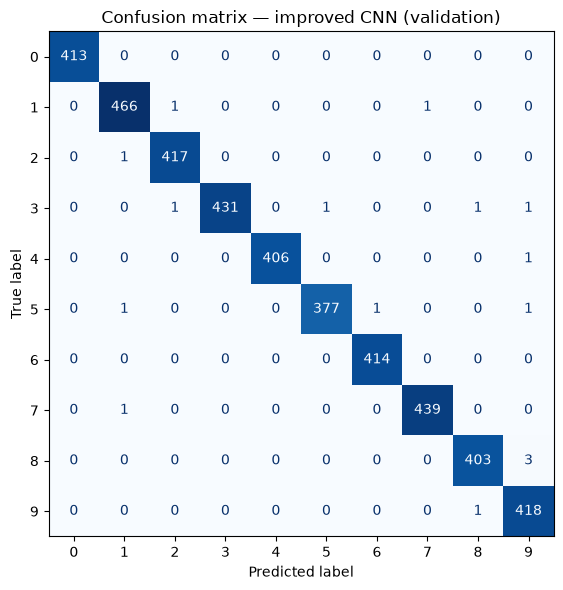

In [11]:
val_pred = predict_labels(improved, val_loader, device)
print("Validation accuracy:", (val_pred == y_val).mean().round(4))
fig, cm = plot_confusion_matrix(y_val, val_pred, title="Confusion matrix — improved CNN (validation)",
                                path=RESULTS_DIR / "confusion_matrix.png")
plt.show()

In [12]:
# Most frequent confusions (true -> predicted), ignoring the diagonal
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], i, j) for i in range(10) for j in range(10) if off[i, j] > 0), reverse=True)
print("Most frequent errors:")
for n, i, j in pairs[:6]:
    print(f"  true {i} -> predicted {j}: {n}")
per_class = cm.diagonal() / cm.sum(axis=1)
print("\nPer-class accuracy:", {d: round(float(a), 4) for d, a in enumerate(per_class)})

Most frequent errors:
  true 8 -> predicted 9: 3
  true 9 -> predicted 8: 1
  true 7 -> predicted 1: 1
  true 5 -> predicted 9: 1
  true 5 -> predicted 6: 1
  true 5 -> predicted 1: 1

Per-class accuracy: {0: 1.0, 1: 0.9957, 2: 0.9976, 3: 0.9908, 4: 0.9975, 5: 0.9921, 6: 1.0, 7: 0.9977, 8: 0.9926, 9: 0.9976}


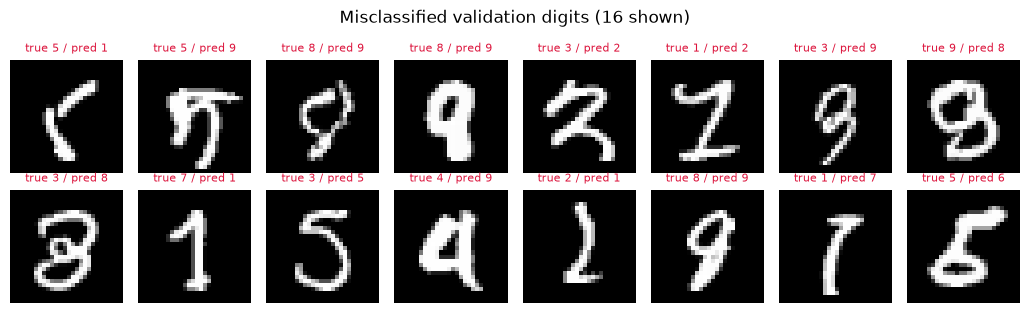

In [13]:
plot_misclassified(X_val, y_val, val_pred, n=24, path=RESULTS_DIR / "misclassified_digits.png")
plt.show()

we have a 16/4200 wrong vdidation digits. the errors are (8→9, 5→6 and 3→9 twice each). the image shows the mistakes that i would get wrong too. and there is a few mislabelled so the error we can put to a noise of the tem. 

## 9. Kaggle submission

We predict the 28,000 test images with the improved CNN. The test loader is never shuffled, so row *i* corresponds to `ImageId = i + 1`. and we get the `.csv` that is needed for submision. 

In [14]:
test_loader = make_test_loader(X_test, MEAN, STD)
test_pred = predict_labels(improved, test_loader, device)
submission = make_submission(test_pred, RESULTS_DIR / "submission.csv")

print(submission.head())
print("Rows:", len(submission), "| format OK:", check_submission(submission))
print("Predicted class distribution:", np.bincount(test_pred, minlength=10))

   ImageId  Label
0        1      2
1        2      0
2        3      9
3        4      0
4        5      3
Rows: 28000 | format OK: True
Predicted class distribution: [2769 3193 2811 2791 2756 2507 2751 2897 2749 2776]


In [15]:
metrics = {
    "seed": SEED,
    "device": str(device),
    "n_train": int(len(y_train)),
    "n_val": int(len(y_val)),
    "mean": MEAN,
    "std": STD,
    "models": {
        name: {"best_val_acc": h["best_val_acc"], "best_epoch": h["best_epoch"],
               "epochs": len(h["val_acc"]), "final_train_acc": h["train_acc"][-1]}
        for name, h in histories.items()
    },
    "top_confusions": [{"true": int(i), "pred": int(j), "count": int(n)} for n, i, j in pairs[:6]],
}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
torch.save(improved.state_dict(), RESULTS_DIR / "improved_cnn.pt")
print(json.dumps(metrics["models"], indent=2))

{
  "MLP": {
    "best_val_acc": 0.9785714285714285,
    "best_epoch": 9,
    "epochs": 10,
    "final_train_acc": 0.9946296296296296
  },
  "CNN": {
    "best_val_acc": 0.9897619047619047,
    "best_epoch": 7,
    "epochs": 10,
    "final_train_acc": 0.9972486772486773
  },
  "Improved CNN": {
    "best_val_acc": 0.9961904761904762,
    "best_epoch": 15,
    "epochs": 15,
    "final_train_acc": 0.9928042328042328
  }
}


## 10. Extra improvement: ensemble of 5 improved CNNs -this is with help of AI

An to train several of the same model but with diferent random seeds and avg their predicted the probabilities mosething like soft voting. eveyry coppy will make different mistakes, so when averaged is more or less more accurate than any single model, by it self .

Two steps:
1. **Check on validation**: train 5 improved CNNs (seeds 0–4) on the same 90% training split and measure the ensemble on the validation set, to see whether it really beats the single improved CNN.
2. **Final models**: 5 models a re trained on **all 42,000 labelled images** (train + validation). NO validation set is left, the weights of each model is lef after the last epoch. The normalisation sstayes thesame and is reused.

The ensemble predictions are saved as `results/submission_ensemble.csv`, so the single-model `submission.csv` is kept.

In [16]:
from digit_recognizer import predict_ensemble

SEEDS = [0, 1, 2, 3, 4]
ENS_EPOCHS = 15

ens_models = []
for s in SEEDS:
    set_seed(s)
    loader_s, _ = make_loaders(X_train, y_train, X_val, y_val, MEAN, STD,
                               batch_size=BATCH_SIZE, augment=True, seed=s)
    m = build_model("improved_cnn")
    h = fit(m, loader_s, val_loader, device, epochs=ENS_EPOCHS, lr=1e-3,
            scheduler="cosine", label_smoothing=0.1, verbose=False)
    ens_models.append(m)
    print(f"seed {s}: validation accuracy {h['best_val_acc']:.4f}")

ens_val_pred = predict_ensemble(ens_models, val_loader, device)
ens_val_acc = float((ens_val_pred == y_val).mean())
print(f"\nSingle improved CNN: {hist_improved['best_val_acc']:.4f} "
      f"({int(round((1 - hist_improved['best_val_acc']) * len(y_val)))} errors)")
print(f"Ensemble of {len(SEEDS)}:      {ens_val_acc:.4f} ({int((ens_val_pred != y_val).sum())} errors)")

seed 0: validation accuracy 0.9967
seed 1: validation accuracy 0.9967
seed 2: validation accuracy 0.9967
seed 3: validation accuracy 0.9964
seed 4: validation accuracy 0.9964

Single improved CNN: 0.9962 (16 errors)
Ensemble of 5:      0.9971 (12 errors)


In [17]:
X_full = np.concatenate([X_train, X_val])
y_full = np.concatenate([y_train, y_val])
print("Training the final models on", len(y_full), "images")

full_models = []
for s in SEEDS:
    set_seed(s)
    loader_full, _ = make_loaders(X_full, y_full, X_val, y_val, MEAN, STD,
                                  batch_size=BATCH_SIZE, augment=True, seed=s)
    m = build_model("improved_cnn")
    fit(m, loader_full, None, device, epochs=ENS_EPOCHS, lr=1e-3,
        scheduler="cosine", label_smoothing=0.1, verbose=False)
    full_models.append(m)
    print(f"seed {s}: done")

test_pred_ens = predict_ensemble(full_models, test_loader, device)
submission_ens = make_submission(test_pred_ens, RESULTS_DIR / "submission_ensemble.csv")
print("Rows:", len(submission_ens), "| format OK:", check_submission(submission_ens))
print("Test predictions that differ from the single improved CNN:", int((test_pred_ens != test_pred).sum()))

metrics["ensemble"] = {"seeds": SEEDS, "epochs": ENS_EPOCHS, "val_acc_90pct_models": ens_val_acc,
                       "final_models_trained_on": int(len(y_full))}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))

Training the final models on 42000 images
seed 0: done
seed 1: done
seed 2: done
seed 3: done
seed 4: done
Rows: 28000 | format OK: True
Test predictions that differ from the single improved CNN: 37


1207